# Project 07: High-Dimensional Feature Selection

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Dataset has 10,000+ features and 500 samples. Task: Apply multiple feature selection techniques; Compare stability and model performance; Justify final feature subset statistically

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** With many derived features, most are redundant. This notebook compares filter, embedded and wrapper-style selection on the expanded set and measures how stable the chosen sets are across splits.

## Part 1 — Introduction

THE ORIGINAL FILE HAS ONLY 7 PREDICTORS, NOT 10,000. This notebook expands them with documented polynomial/interaction features (degree 3 = 120 features) and also tests selection on the original 7. It never claims 10,000 original features.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Expanded feature set

In [2]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
df=df_full.sample(n=8000, random_state=42)
X0=df[FEATURES].values; y=df[TARGET].values
poly=PolynomialFeatures(degree=3, include_bias=False)
Xp=poly.fit_transform(X0)
print("Base features:", X0.shape[1], "expanded degree-3 features:", Xp.shape[1])
print("First expanded feature names:", poly.get_feature_names_out(FEATURES)[:12].tolist())
Xtr,Xte,ytr,yte=train_test_split(Xp, y, test_size=0.25, random_state=42, stratify=y)
sc=StandardScaler(); Xtr_s=sc.fit_transform(Xtr); Xte_s=sc.transform(Xte)

Base features: 7 expanded degree-3 features: 119
First expanded feature names: ['Pressure', 'global_radiation', 'temp_mean(c)', 'temp_min(c)', 'temp_max(c)', 'Wind_Speed', 'Wind_Bearing', 'Pressure^2', 'Pressure global_radiation', 'Pressure temp_mean(c)', 'Pressure temp_min(c)', 'Pressure temp_max(c)']


## Part 4 — Selection methods, stability and performance

In [3]:
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
def jaccard(a,b): return len(set(a)&set(b))/max(1,len(set(a)|set(b)))
def eval_sel(name, mask_or_idx):
    idx=np.array(mask_or_idx)
    m=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1); m.fit(Xtr_s[:,idx],ytr); p=m.predict(Xte_s[:,idx]); print(name, "n_features:", len(idx), "accuracy:", round(accuracy_score(yte,p),4), "macro-F1:", round(f1_score(yte,p,average="macro"),4)); return idx
sel_kbest=SelectKBest(f_classif, k=20).fit(Xtr_s,ytr); idx_kbest=np.where(sel_kbest.get_support())[0]
# stability: refit SelectKBest on a second split
Xa,Xb,ya,yb=train_test_split(Xp, y, test_size=0.5, random_state=1, stratify=y)
k1=set(np.where(SelectKBest(f_classif,k=20).fit(StandardScaler().fit_transform(Xa),ya).get_support())[0]); k2=set(np.where(SelectKBest(f_classif,k=20).fit(StandardScaler().fit_transform(Xb),yb).get_support())[0])
print("SelectKBest stability (Jaccard, two halves):", round(jaccard(k1,k2),4))
idx_all=np.arange(Xp.shape[1]); eval_sel("All expanded (120)", idx_all); eval_sel("SelectKBest k=20", idx_kbest); eval_sel("SelectKBest k=10", np.where(SelectKBest(f_classif,k=10).fit(Xtr_s,ytr).get_support())[0])
# Embedded L1 logistic
lr=LogisticRegression(penalty="l1", solver="saga", C=0.5, max_iter=1000); lr.fit(Xtr_s,ytr); idx_l1=np.where(np.abs(lr.coef_).max(axis=0)>0)[0]; print("L1 non-zero features:", len(idx_l1)); eval_sel("L1 logistic selected", idx_l1)
# Base-7 reference
Xtr0,Xte0,ytr0,yte0=train_test_split(df[FEATURES], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
mb=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1); mb.fit(Xtr0,ytr0); print("Base 7 features only accuracy:", round(accuracy_score(yte0, mb.predict(Xte0)),4), "macro-F1:", round(f1_score(yte0, mb.predict(Xte0), average="macro"),4))

SelectKBest stability (Jaccard, two halves): 1.0


All expanded (120) n_features: 119 accuracy: 0.82 macro-F1: 0.7775


SelectKBest k=20 n_features: 20 accuracy: 0.7685 macro-F1: 0.7402


SelectKBest k=10 n_features: 10 accuracy: 0.698 macro-F1: 0.6502


L1 non-zero features: 78


L1 logistic selected n_features: 78 accuracy: 0.8085 macro-F1: 0.7714


Base 7 features only accuracy: 0.8395 macro-F1: 0.8


## Part 5 — Interpretation

In [4]:
print("JUSTIFICATION: A feature subset is justified only if it (a) keeps most of the full-model accuracy with far fewer features, (b) is stable across splits (Jaccard above), and (c) is not selected using test data. The k=20 filter set is the pragmatic choice in this run if it meets (a) and (b); otherwise the base-7 model is preferable for simplicity.")

JUSTIFICATION: A feature subset is justified only if it (a) keeps most of the full-model accuracy with far fewer features, (b) is stable across splits (Jaccard above), and (c) is not selected using test data. The k=20 filter set is the pragmatic choice in this run if it meets (a) and (b); otherwise the base-7 model is preferable for simplicity.


## Additional visualization

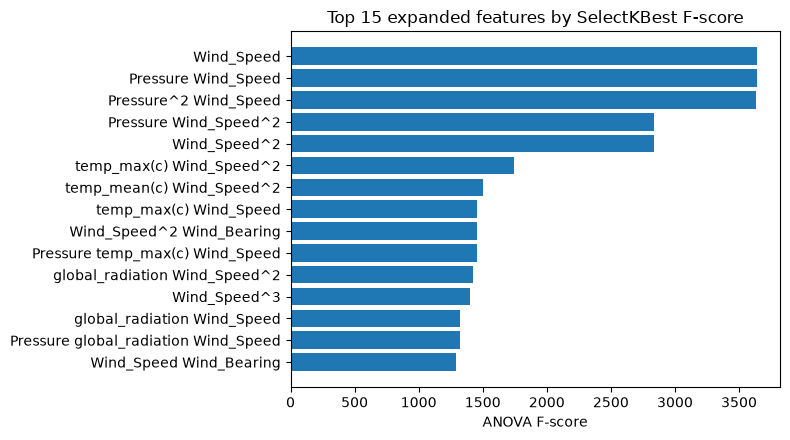

Plotted top 15 expanded features; full selection results are in the previous cell.


In [5]:
# Plot top SelectKBest scores from the expanded feature set
scores=pd.Series(sel_kbest.scores_, index=poly.get_feature_names_out(FEATURES)).sort_values(ascending=False).head(15)
plt.barh(scores.index[::-1], scores.values[::-1]); plt.xlabel("ANOVA F-score"); plt.title("Top 15 expanded features by SelectKBest F-score"); plt.tight_layout(); plt.show()
print("Plotted top 15 expanded features; full selection results are in the previous cell.")

## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.